# Full closed-loop agent recovery
Run after `run_full_agent_recovery.py` completes.

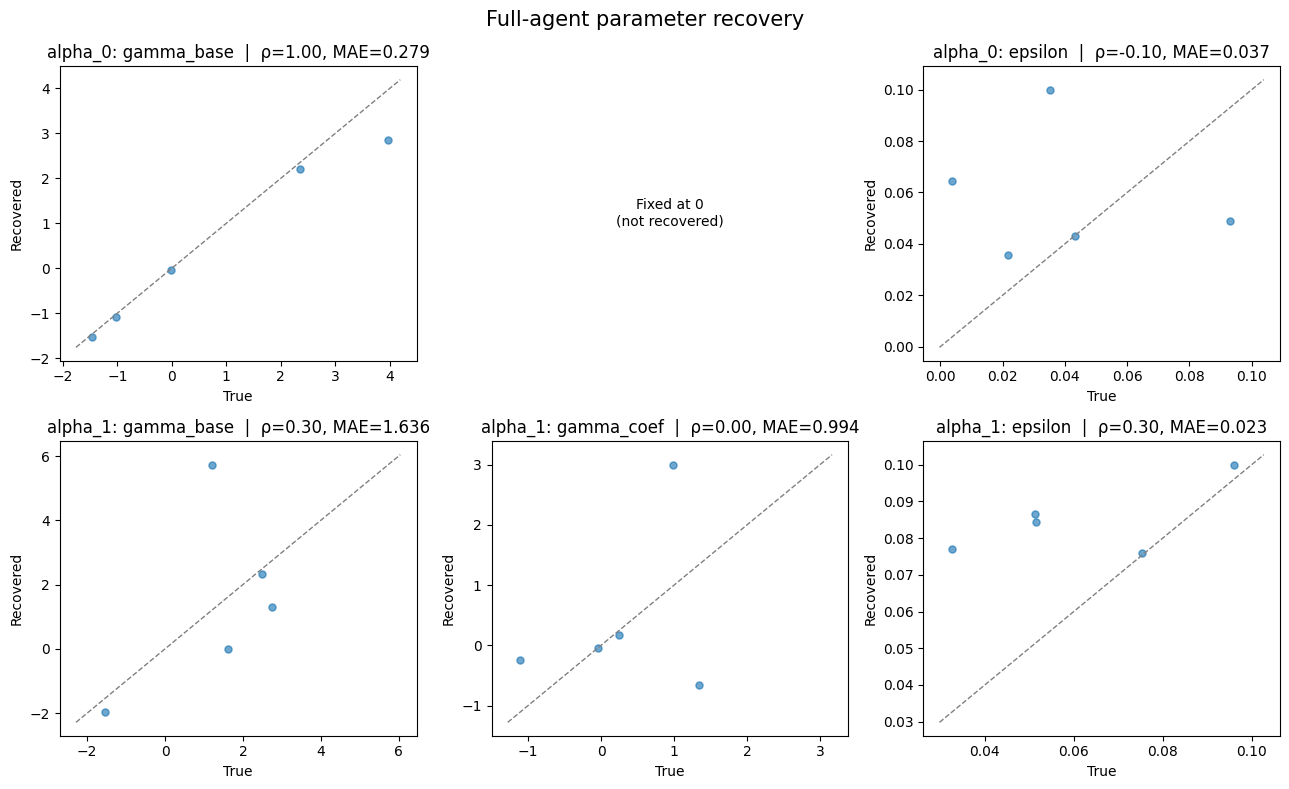

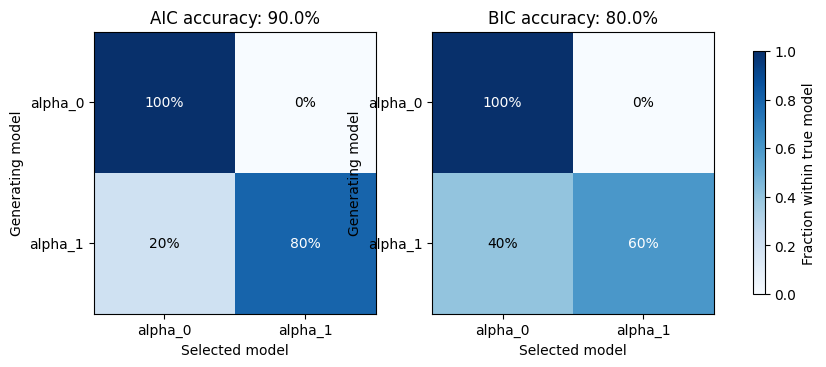

,model,parameter,N,spearman_rho,bias,MAE,RMSE
0,alpha_0,gamma_base,5,1.0,-0.279,0.279,0.506
1,alpha_0,epsilon,5,-0.1,0.019,0.037,0.045
2,alpha_1,gamma_base,5,0.3,0.175,1.636,2.253
3,alpha_1,gamma_coef,5,0.0,0.158,0.994,1.328
4,alpha_1,epsilon,5,0.3,0.023,0.023,0.029


Completed agents: 10; average observed choices: 181.9
Plots and stats saved to: c:\Users\zyfxl\OneDrive - University of Southern California\Documents\GitHub\foraging_kids_4blocks_Yifan\modeling\full_agent_recovery\pilot_v1\figures


In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display

# Set this to the same RUN_NAME as run_full_agent_recovery.py
RUN_NAME = "pilot_v1"
ROOT = Path.cwd() / "full_agent_recovery" / RUN_NAME
FIG = ROOT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

matched = pd.read_csv(ROOT / "recovery_matched.csv")
comp = pd.read_csv(ROOT / "model_recovery.csv")

# True versus recovered parameters: separate generating models
models = ["alpha_0", "alpha_1"]
params = ["gamma_base", "gamma_coef", "epsilon"]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
summary = []
for r, model in enumerate(models):
    subset = matched[matched.generating_model == model]
    for c, name in enumerate(params):
        ax = axes[r, c]
        if model == "alpha_0" and name == "gamma_coef":
            ax.text(0.5, 0.5, "Fixed at 0\n(not recovered)",
                    ha="center", va="center", transform=ax.transAxes)
            ax.axis("off")
            continue
        v = subset[["true_" + name, "fitted_" + name]].dropna()
        if v.empty:
            ax.axis("off")
            continue
        x, y = v.iloc[:, 0].to_numpy(), v.iloc[:, 1].to_numpy()
        lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
        span = max(hi-lo, 1e-6)
        ax.scatter(x, y, s=26, alpha=.65)
        ax.plot([lo-span*.04, hi+span*.04], [lo-span*.04, hi+span*.04],
                "--", color="gray", linewidth=1)
        rho = spearmanr(x, y).statistic if len(x)>=4 and len(set(x))>1 and len(set(y))>1 else np.nan
        mae = np.mean(np.abs(y-x))
        ax.set(title=f"{model}: {name}  |  ρ={rho:.2f}, MAE={mae:.3f}",
               xlabel="True", ylabel="Recovered")
        summary.append(dict(model=model, parameter=name, N=len(v),
                            spearman_rho=rho, bias=np.mean(y-x),
                            MAE=mae, RMSE=np.sqrt(np.mean((y-x)**2))))
fig.suptitle("Full-agent parameter recovery", fontsize=15)
fig.tight_layout()
fig.savefig(FIG / "parameter_recovery.png", dpi=300, bbox_inches="tight")
plt.show()

# Model recovery: columns are selected model, rows are generating model
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, crit in zip(axes, ["AIC", "BIC"]):
    tab = pd.crosstab(comp.generating_model, comp[f"selected_by_{crit}"],
                      normalize="index").reindex(index=models, columns=models, fill_value=0)
    im = ax.imshow(tab.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks([0,1], models)
    ax.set_yticks([0,1], models)
    ax.set(xlabel="Selected model", ylabel="Generating model",
           title=f"{crit} accuracy: {comp[f'correct_by_{crit}'].mean():.1%}")
    for (i,j), val in np.ndenumerate(tab.values):
        ax.text(j, i, f"{val:.0%}", ha="center", va="center",
                color="white" if val>.55 else "black")
fig.colorbar(im, ax=axes.tolist(), shrink=.75, label="Fraction within true model")
fig.savefig(FIG / "model_recovery_confusion.png", dpi=300, bbox_inches="tight")
plt.show()

summary_df = pd.DataFrame(summary)
summary_df.to_csv(ROOT / "recovery_statistics.csv", index=False)
display(summary_df.round(3))
print(f"Completed agents: {len(matched)}; average observed choices: {matched.n_choices.mean():.1f}")
print(f"Plots and stats saved to: {FIG}")
